<a href="https://colab.research.google.com/github/saisudhanv/ML-Practice/blob/main/AdaBoost_hyperparameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

In [3]:
np.random.seed(45)

In [4]:
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)

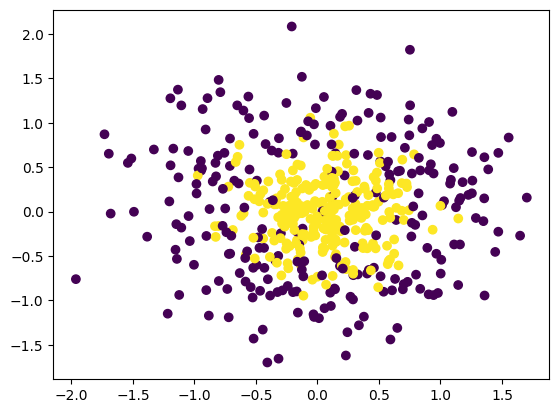

In [5]:
plt.scatter(X[:,0],X[:,1],c=y)

In [6]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

In [7]:
abc = AdaBoostClassifier()

In [8]:
np.mean(cross_val_score(abc, X, y, scoring = 'accuracy', cv = 10))

np.float64(0.812)

In [10]:
abc.fit(X, y)

AdaBoostClassifier()

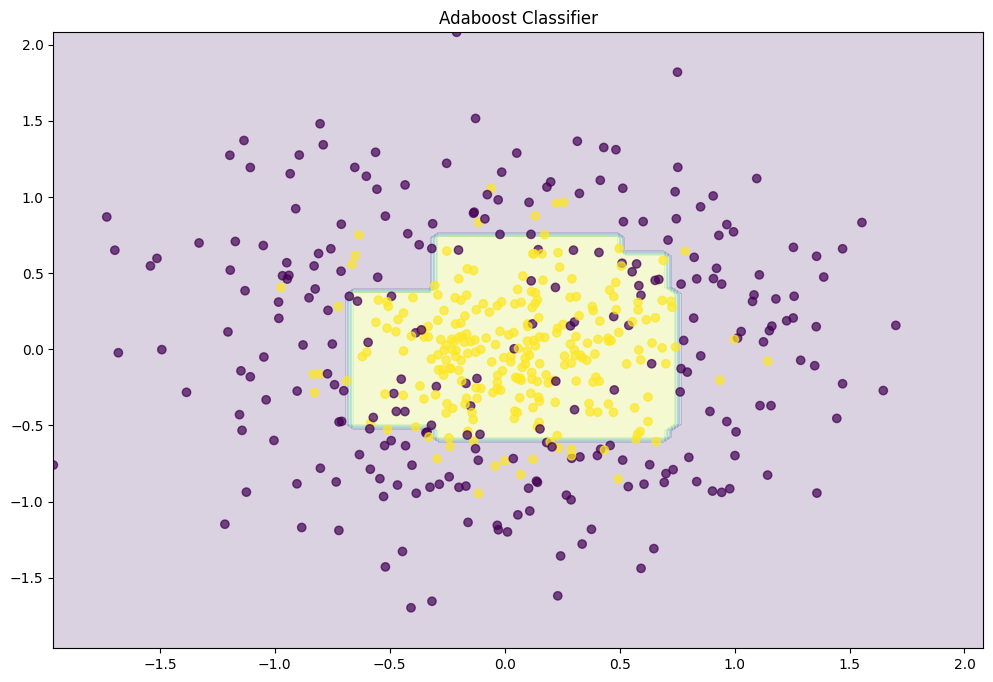

In [11]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    xx1, xx2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1, xx2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    plt.title("Adaboost Classifier")
    plt.show()

plot_decision_boundary(abc)

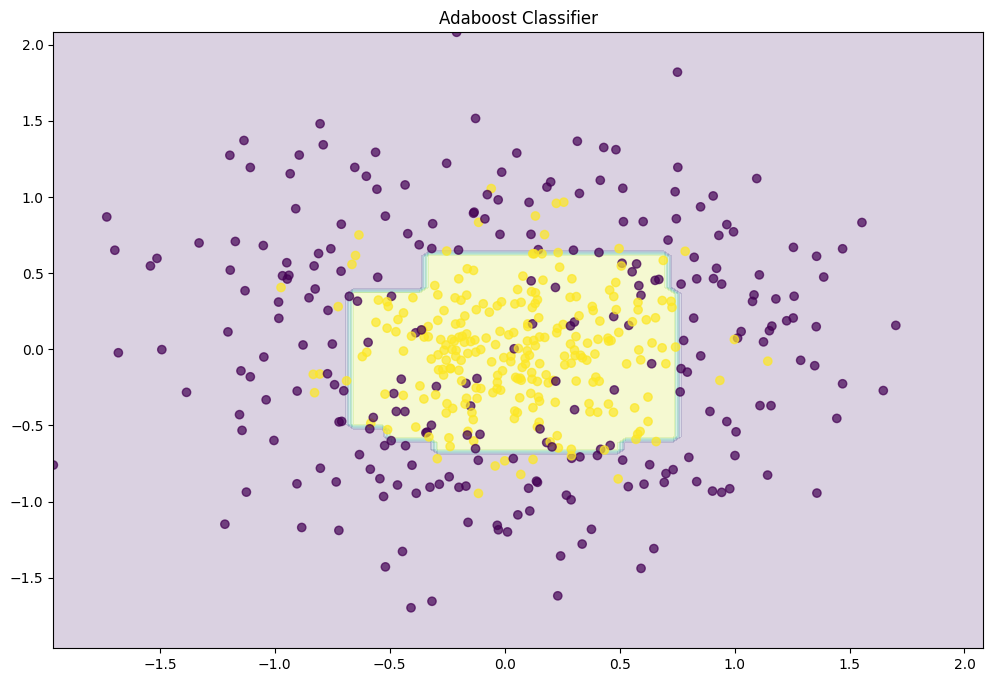

In [14]:
abc = AdaBoostClassifier(n_estimators=1500,learning_rate=0.1)
abc.fit(X,y)
plot_decision_boundary(abc)

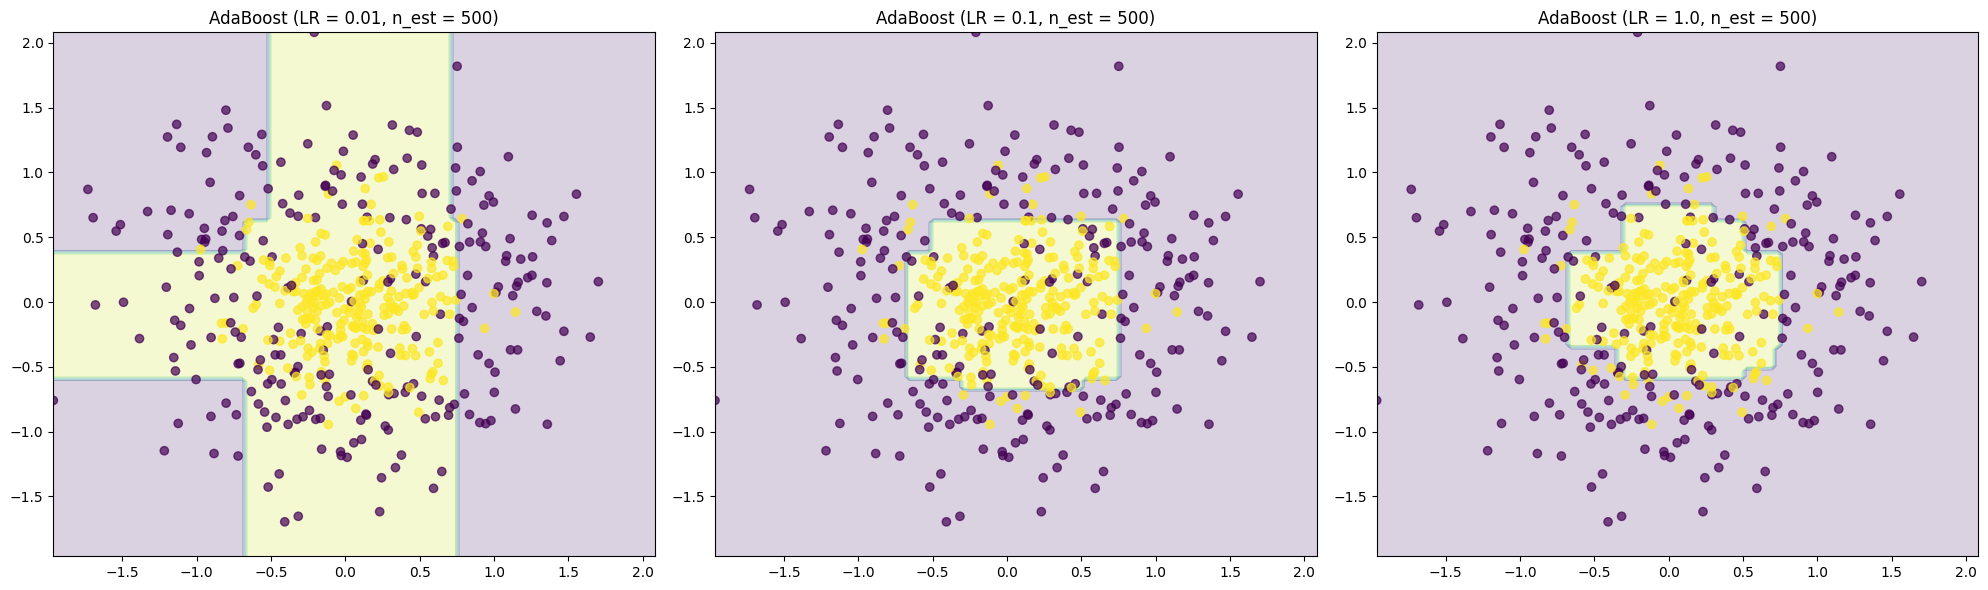

In [15]:
# Compare different learning rates with fixed number of estimators
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

learning_rates = [0.01, 0.1, 1.0]
x_range = np.linspace(X.min(), X.max(), 100)
xx1, xx2 = np.meshgrid(x_range, x_range)

for i, lr in enumerate(learning_rates):
    # Initialize and fit the model with specific learning rate
    model = AdaBoostClassifier(n_estimators=500, learning_rate=lr, random_state=42)
    model.fit(X, y)

    # Predict over the meshgrid
    y_hat = model.predict(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

    # Plot on the corresponding subplot
    ax = axes[i]
    ax.contourf(xx1, xx2, y_hat, alpha=0.2, cmap='viridis')
    ax.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    ax.set_title(f"AdaBoost (LR = {lr}, n_est = 500)")

plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import GridSearchCV

In [19]:
# Cleaned Grid Search without the deprecated 'algorithm' parameter
grid = dict()
grid['n_estimators'] = [10, 50, 100, 500]
grid['learning_rate'] = [0.0001, 0.001, 0.01, 0.1, 1.0]

grid_search = GridSearchCV(estimator=AdaBoostClassifier(random_state=42), param_grid=grid, n_jobs=-1, cv=10, scoring='accuracy')
grid_result = grid_search.fit(X, y)

print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: 0.832000 using {'learning_rate': 0.1, 'n_estimators': 500}
